In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")


All libraries imported successfully!


In [3]:
df = pd.read_csv("retail_sales_dataset.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,10,2023-10-07,CUST010,Female,52,Clothing,4,50,200
1,11,2023-02-14,CUST011,Male,23,Clothing,2,50,100
2,12,2023-10-30,CUST012,Male,35,Beauty,3,25,75
3,13,2023-08-05,CUST013,Male,22,Electronics,3,500,1500
4,14,2023-01-17,CUST014,Male,64,Clothing,4,30,120


In [5]:
print("Shape of Dataset:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

Shape of Dataset: (972, 9)

Column Names:
Index(['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age',
       'Product Category', 'Quantity', 'Price per Unit', 'Total Amount'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 972 entries, 0 to 971
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    972 non-null    int64 
 1   Date              972 non-null    object
 2   Customer ID       972 non-null    object
 3   Gender            972 non-null    object
 4   Age               972 non-null    int64 
 5   Product Category  972 non-null    object
 6   Quantity          972 non-null    int64 
 7   Price per Unit    972 non-null    int64 
 8   Total Amount      972 non-null    int64 
dtypes: int64(5), object(4)
memory usage: 68.5+ KB


In [6]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64


In [7]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [8]:
print("Mean:")
print(df[['Age', 'Quantity', 'Price per Unit', 'Total Amount']].mean())

print("\nMedian:")
print(df[['Age', 'Quantity', 'Price per Unit', 'Total Amount']].median())

print("\nMode:")
print(df[['Age', 'Quantity', 'Price per Unit', 'Total Amount']].mode().iloc[0])

print("\nStandard Deviation:")
print(df[['Age', 'Quantity', 'Price per Unit', 'Total Amount']].std())

Mean:
Age                41.468107
Quantity            2.515432
Price per Unit    180.699588
Total Amount      459.068930
dtype: float64

Median:
Age                42.0
Quantity            3.0
Price per Unit     50.0
Total Amount      150.0
dtype: float64

Mode:
Age               51.0
Quantity           4.0
Price per Unit    25.0
Total Amount      50.0
Name: 0, dtype: float64

Standard Deviation:
Age                13.681985
Quantity            1.134048
Price per Unit    190.288480
Total Amount      563.443037
dtype: float64


In [9]:
df['Date'] = pd.to_datetime(df['Date'])

df['Month'] = df['Date'].dt.to_period('M')

monthly_sales = df.groupby('Month')['Total Amount'].sum()

print(monthly_sales)

Month
2023-01    34320
2023-02    42935
2023-03    28740
2023-04    33540
2023-05    52550
2023-06    36445
2023-07    35165
2023-08    36960
2023-09    22370
2023-10    46520
2023-11    31050
2023-12    44090
2024-01     1530
Freq: M, Name: Total Amount, dtype: int64


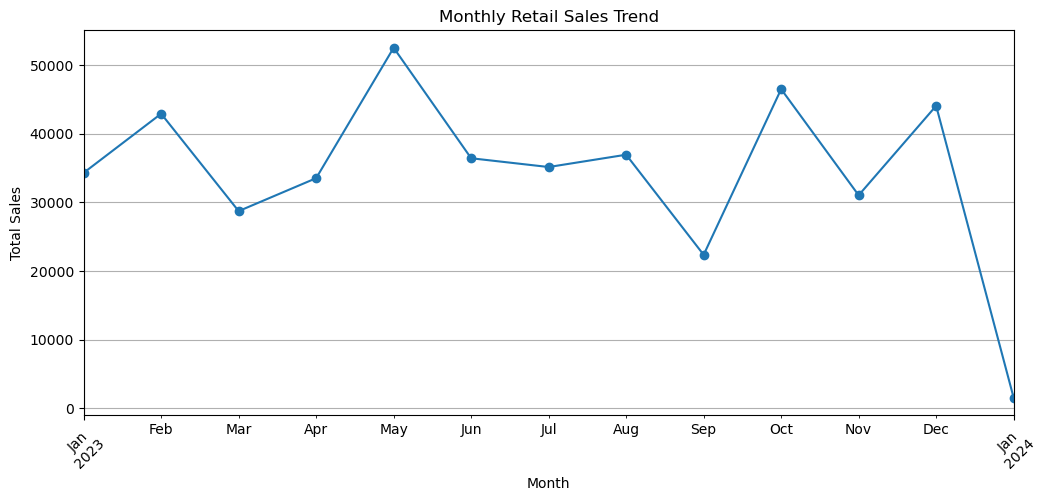

In [10]:
plt.figure(figsize=(12, 5))

monthly_sales.plot(kind='line', marker='o')

plt.title('Monthly Retail Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

In [11]:
df['Quarter'] = df['Date'].dt.to_period('Q')

quarterly_sales = df.groupby('Quarter')['Total Amount'].sum()

print(quarterly_sales)


Quarter
2023Q1    105995
2023Q2    122535
2023Q3     94495
2023Q4    121660
2024Q1      1530
Freq: Q-DEC, Name: Total Amount, dtype: int64


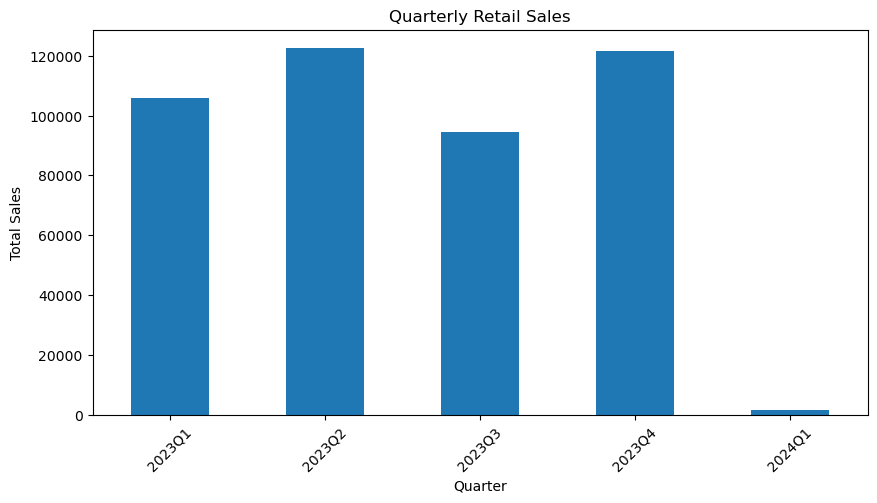

In [12]:
plt.figure(figsize=(10, 5))

quarterly_sales.plot(kind='bar')

plt.title('Quarterly Retail Sales')
plt.xlabel('Quarter')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)

plt.show()

In [13]:
gender_count = df['Gender'].value_counts()

print("Customer Count by Gender:")
print(gender_count)

gender_sales = df.groupby('Gender')['Total Amount'].sum()

print("\nSales by Gender:")
print(gender_sales)

Customer Count by Gender:
Gender
Female    501
Male      471
Name: count, dtype: int64

Sales by Gender:
Gender
Female    229360
Male      216855
Name: Total Amount, dtype: int64


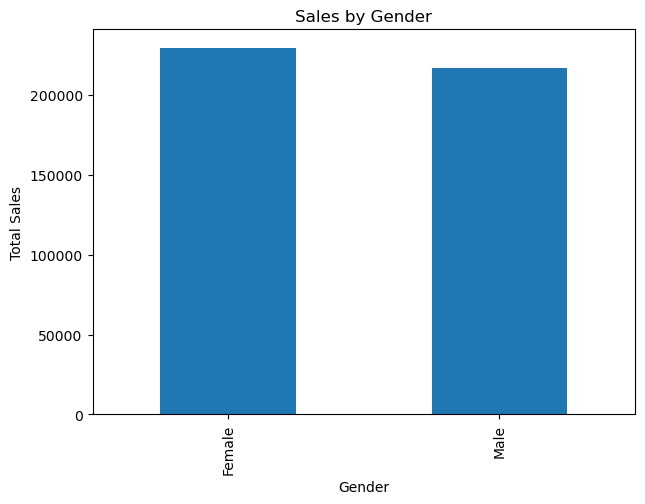

In [14]:
plt.figure(figsize=(7, 5))

gender_sales.plot(kind='bar')

plt.title('Sales by Gender')
plt.xlabel('Gender')
plt.ylabel('Total Sales')

plt.show()

In [15]:
bins = [0, 25, 35, 50, 100]

labels = ['18-25', '26-35', '36-50', '51+']

df['Age Group'] = pd.cut(df['Age'], bins=bins, labels=labels)

age_count = df['Age Group'].value_counts().sort_index()

print("Customer Count by Age Group:")
print(age_count)

Customer Count by Age Group:
Age Group
18-25    164
26-35    197
36-50    303
51+      308
Name: count, dtype: int64


In [16]:
age_sales = df.groupby('Age Group', observed=False)['Total Amount'].sum()

print("Sales by Age Group:")
print(age_sales)

Sales by Age Group:
Age Group
18-25     81575
26-35     96480
36-50    136690
51+      131470
Name: Total Amount, dtype: int64


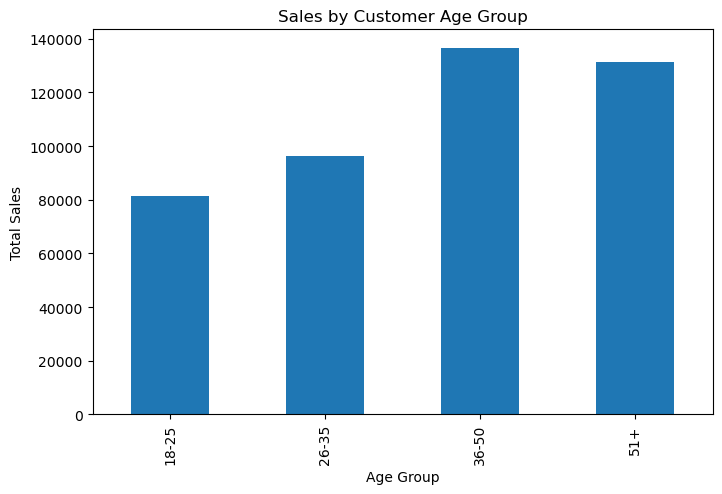

In [17]:
plt.figure(figsize=(8, 5))

age_sales.plot(kind='bar')

plt.title('Sales by Customer Age Group')
plt.xlabel('Age Group')
plt.ylabel('Total Sales')

plt.show()

In [18]:
category_sales = df.groupby('Product Category')['Total Amount'].sum()

print("Revenue by Product Category:")
print(category_sales)

Revenue by Product Category:
Product Category
Beauty         140165
Clothing       151795
Electronics    154255
Name: Total Amount, dtype: int64


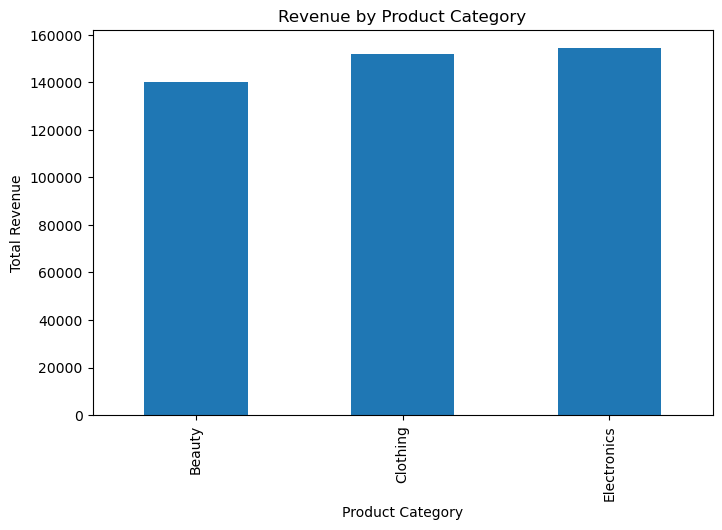

In [19]:
plt.figure(figsize=(8, 5))

category_sales.plot(kind='bar')

plt.title('Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue')

plt.show()

In [20]:
print(df.columns.tolist())

['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount', 'Month', 'Quarter', 'Age Group']


In [21]:
top_10 = df.nlargest(10, 'Total Amount')

print(top_10[['Transaction ID', 'Product Category',
              'Quantity', 'Total Amount']])

     Transaction ID Product Category  Quantity  Total Amount
5                15      Electronics         4          2000
55               65      Electronics         4          2000
62               72      Electronics         4          2000
64               74           Beauty         4          2000
79               89      Electronics         4          2000
83               93           Beauty         4          2000
99              109      Electronics         4          2000
108             118      Electronics         4          2000
114             124         Clothing         4          2000
129             139           Beauty         4          2000


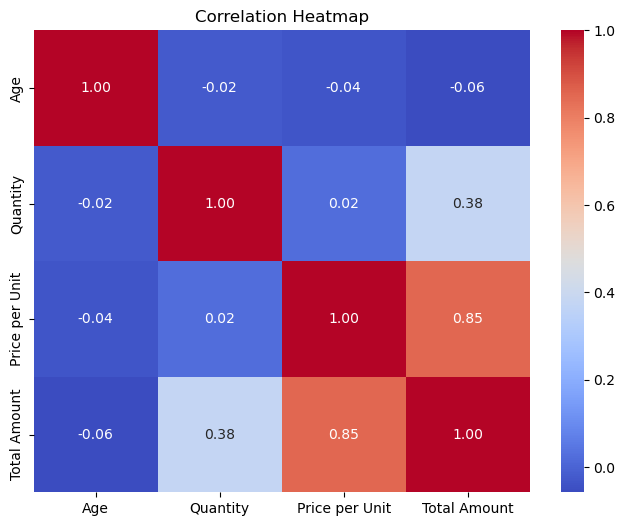

In [22]:
plt.figure(figsize=(8, 6))

correlation = df[
    ['Age', 'Quantity', 'Price per Unit', 'Total Amount']
].corr()

sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap')

plt.show()

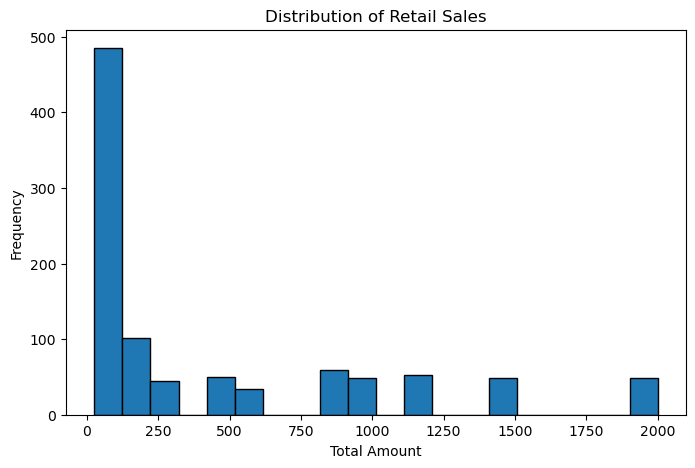

In [23]:
plt.figure(figsize=(8, 5))

plt.hist(df['Total Amount'], bins=20, edgecolor='black')

plt.title('Distribution of Retail Sales')
plt.xlabel('Total Amount')
plt.ylabel('Frequency')

plt.show()

# Final Observations

1. The dataset contains no missing values or duplicate records.

2. The average customer age is approximately 41 years.

3. May 2023 recorded the highest monthly sales of ₹52,550.

4. Female customers generated higher sales than male customers.

5. Customers aged 36-50 generated the highest revenue of ₹1,36,690.

6. Electronics generated the highest category revenue of ₹1,54,255.

7. The highest transaction amount was ₹2,000.

8. Product names are not available in the dataset, so product-level analysis was not possible.

# Business Recommendations

1. Target customers aged 36-50 and 51+ with personalized offers.

2. Promote Electronics products because this category generated the highest revenue.

3. Analyze the reasons for lower sales in September and introduce seasonal offers to improve sales.